In [4]:
%pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
cols = ["unit", "cycle", "op1", "op2", "op3"] + [f"s{i}" for i in range(1, 22)]
train = pd.read_csv("../data/train_FD001.txt", sep=r"\s+", header=None, names=cols)
test = pd.read_csv("../data/test_FD001.txt", sep=r"\s+", header=None, names=cols)
true_rul = pd.read_csv("../data/RUL_FD001.txt", sep=r"\s+", header=None, names=["RUL"])

print(train.shape, test.shape, true_rul.shape)
train.head()

(20631, 26) (13096, 26) (100, 1)


,unit,cycle,op1,op2,op3,s1,s2,s3,s4,s5,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [9]:
train.isna().sum().sum()

np.int64(0)

In [11]:
train["unit"].nunique()

100

In [12]:
train.groupby("unit")["cycle"].max().describe()

count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: cycle, dtype: float64

## Find useless sensors

In [13]:
std = train.drop(columns=["unit", "cycle"]).std().sort_values()
print(std)

s1     0.000000e+00
op3    0.000000e+00
s10    0.000000e+00
s19    0.000000e+00
s18    0.000000e+00
s16    3.469531e-18
s5     5.329200e-15
op2    2.930621e-04
s6     1.388985e-03
op1    2.187313e-03
s15    3.750504e-02
s8     7.098548e-02
s13    7.191892e-02
s21    1.082509e-01
s20    1.807464e-01
s11    2.670874e-01
s2     5.000533e-01
s12    7.375534e-01
s7     8.850923e-01
s17    1.548763e+00
s3     6.131150e+00
s4     9.000605e+00
s14    1.907618e+01
s9     2.208288e+01
dtype: float64


In [14]:
summary = pd.DataFrame({
    "std": train.std(),
    "cv": train.std() / train.mean().abs(),
    "n_unique": train.nunique(),
}).sort_values("cv")
print(summary)

                std            cv  n_unique
s1     0.000000e+00  0.000000e+00         1
op3    0.000000e+00  0.000000e+00         1
s10    0.000000e+00  0.000000e+00         1
s18    0.000000e+00  0.000000e+00         1
s19    0.000000e+00  0.000000e+00         1
s16    3.469531e-18  1.156510e-16         1
s5     5.329200e-15  3.645143e-16         1
s8     7.098548e-02  2.972471e-05        53
s13    7.191892e-02  3.011559e-05        56
s6     1.388985e-03  6.427569e-05         2
s2     5.000533e-01  7.780739e-04       310
s12    7.375534e-01  1.414527e-03       427
s7     8.850923e-01  1.599465e-03       513
s14    1.907618e+01  2.342431e-03      6078
s9     2.208288e+01  2.435994e-03      6403
s3     6.131150e+00  3.854801e-03      3012
s17    1.548763e+00  3.938762e-03        13
s15    3.750504e-02  4.442595e-03      1918
s21    1.082509e-01  4.648014e-03      4745
s20    1.807464e-01  4.656460e-03       120
s11    2.670874e-01  5.618023e-03       159
s4     9.000605e+00  6.388238e-0

In [24]:
drop_cols = ["s1","op3","s5","s10","s16","s18","s19","s6","op1", "op2"]
sensors = [c for c in train.columns if c not in ["unit", "cycle"] + drop_cols]
print(sensors)


['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']


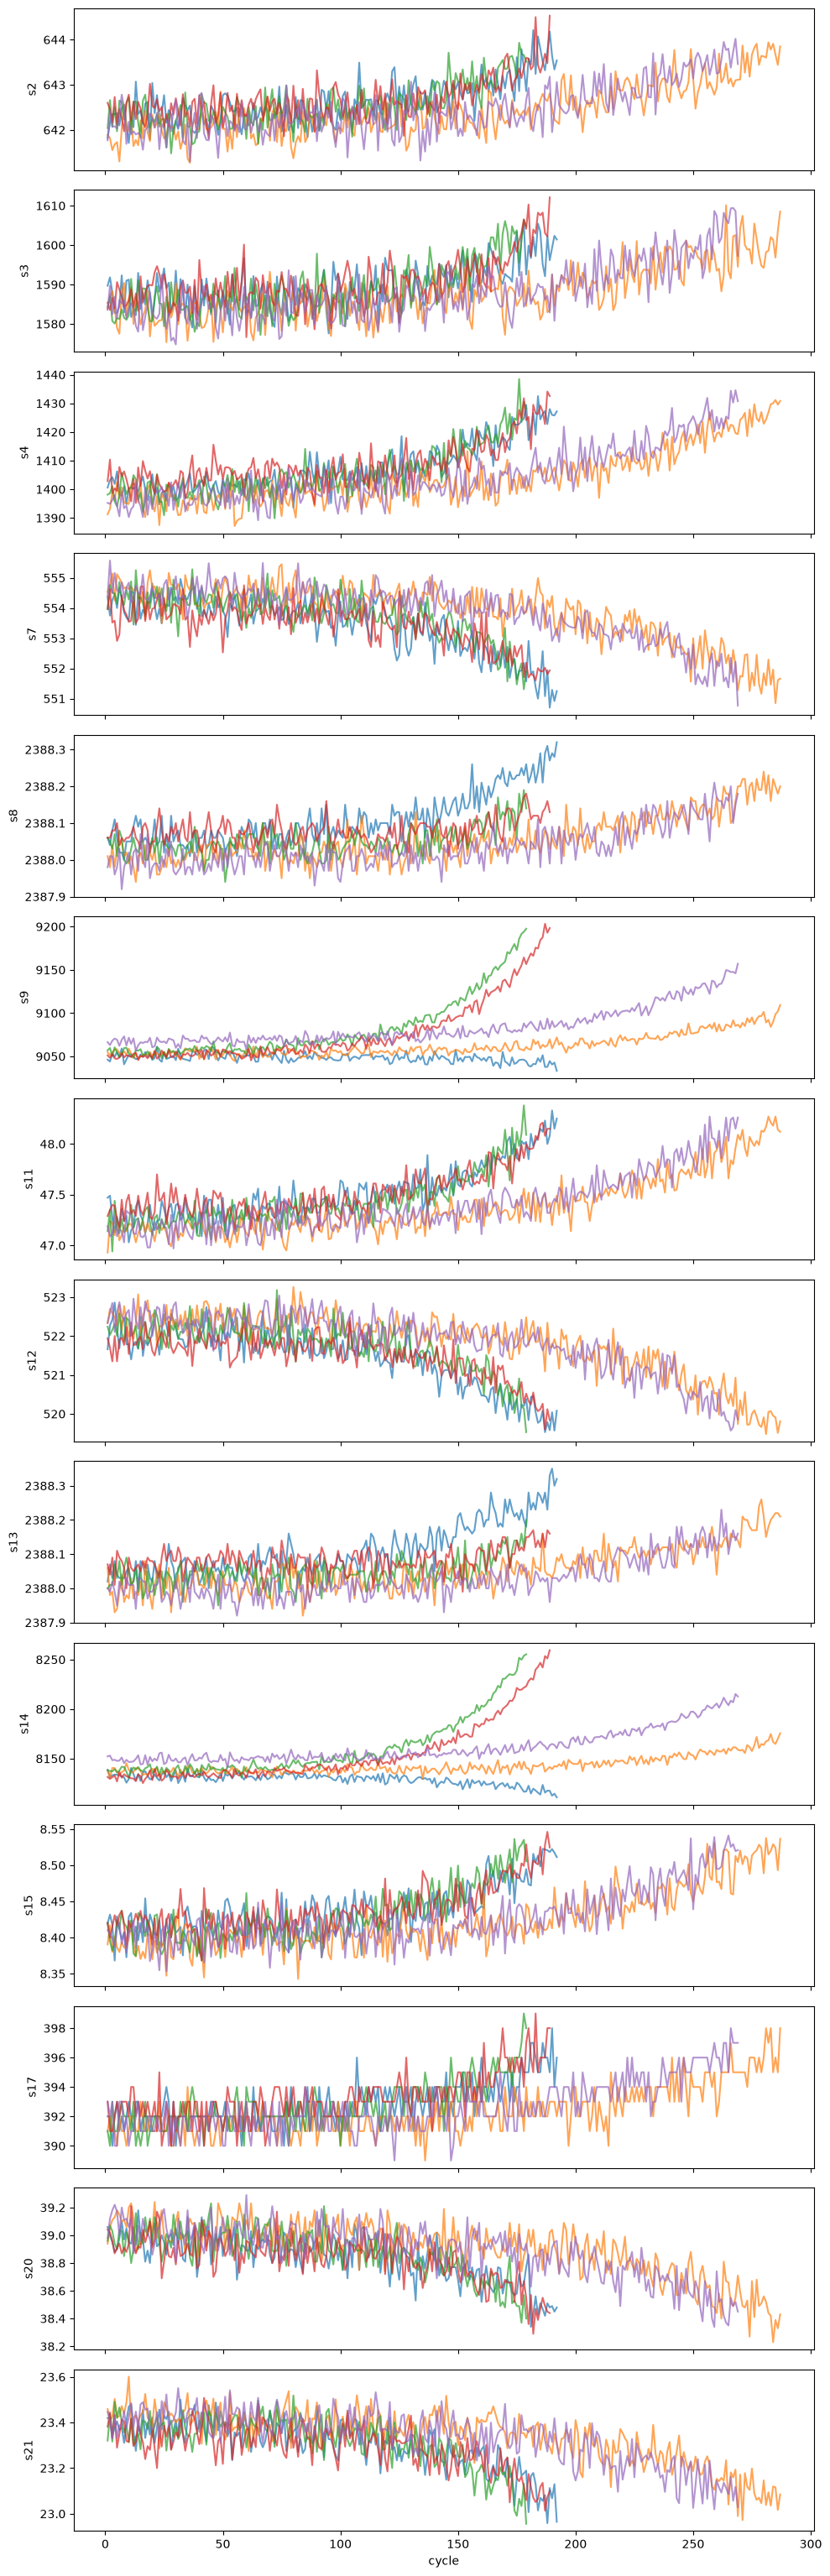

In [25]:
fig, axes = plt.subplots(len(sensors), 1, figsize=(10, 2.2 * len(sensors)), sharex=True)
for ax, s in zip(axes, sensors):
    for u in [1, 2, 3, 4, 5]:
        d = train[train.unit == u]
        ax.plot(d.cycle, d[s], alpha=0.7)
    ax.set_ylabel(s)
plt.xlabel("cycle")
plt.tight_layout()
plt.savefig("../images/sensors.png", dpi=120)
plt.show()

##### We can see that some sensors driftup (s2,s3,s4,s8,s9,s11,s13,s14,s15,s17), and others driftdown (s21, s20,s12,s7) before end of life of engine

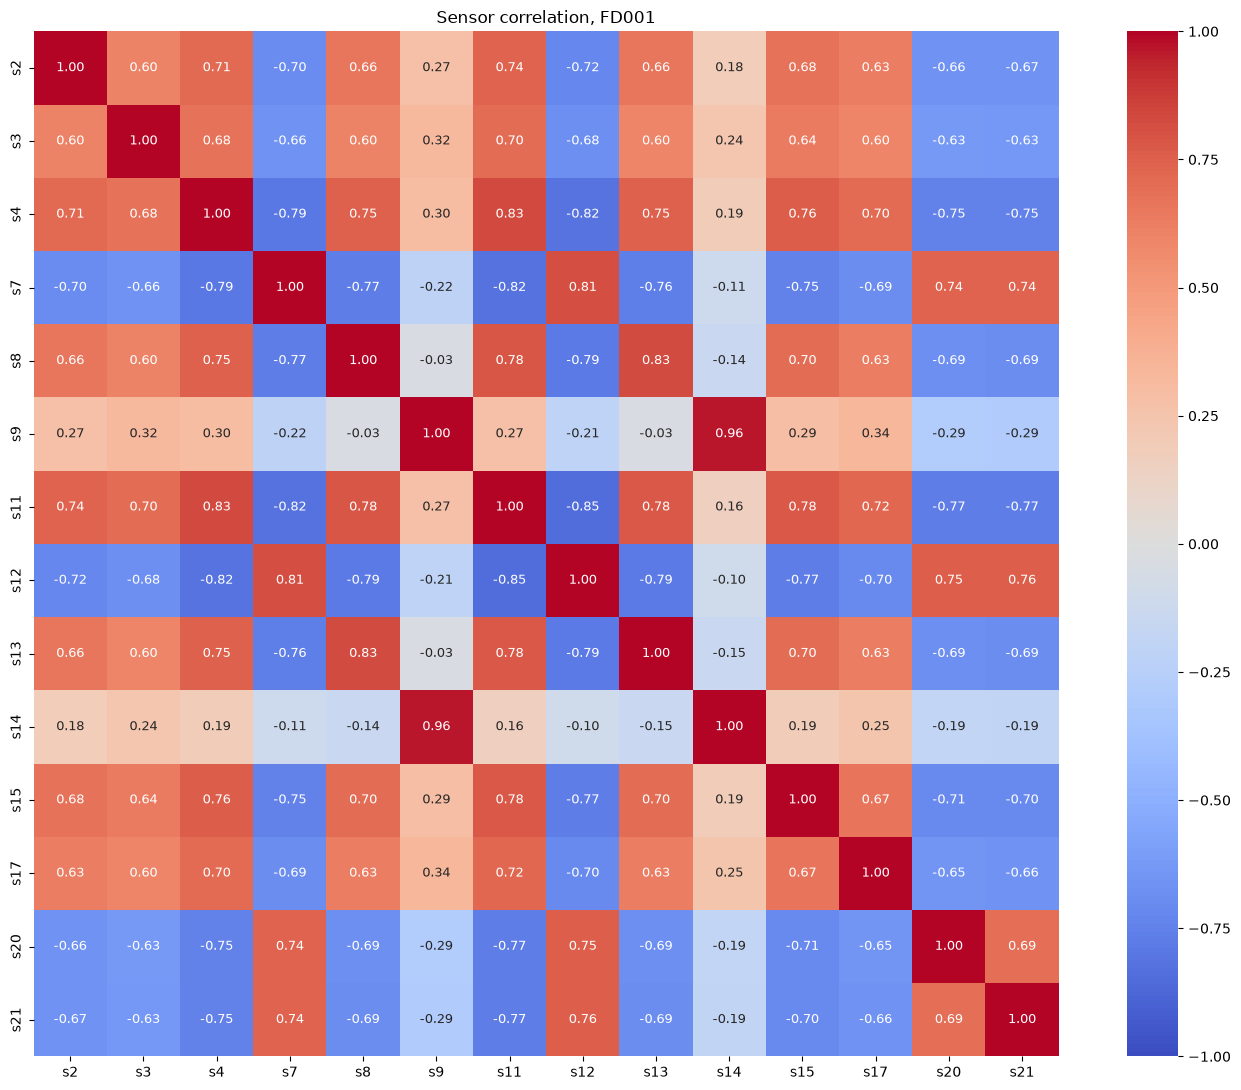

In [ ]:
# Compute correlation matrix
co_mtx = train[sensors].corr()
plt.figure(figsize=(14, 11))
sns.heatmap(
    co_mtx,
    cmap="coolwarm",      
    vmin=-1, vmax=1,   
    annot=True,
    fmt=".2f",            
    annot_kws={"size": 9},
    square=True,
)
plt.title("Sensor correlation, FD001")
plt.tight_layout()
plt.savefig("../images/correlation.png", dpi=120)
plt.show()

In [31]:
pairs = co_mtx.abs().unstack().sort_values(ascending=False)
pairs = pairs[pairs < 1].drop_duplicates()
print(pairs[pairs > 0.9])

s9  s14    0.963157
dtype: float64


#### Both sensors s9 & s14 carry the same information as they are highly correlated (0.96), so in the further analysis these columns should be dropped.